# Пространственная неоднородность кислородной стехиометрии

**Как пользоваться.** Исполните ячейки по порядку в Colab/Jupyter. Примеры со случайной выборкой проверяют поведение уравнений. Параметры рассеяния, число участков и нормировочная длина — настройки численного опыта. Для интерпретации в физических единицах задайте размеры своего образца и измеренные входы. Маркеры на обзорной 3D-картинке показывают центры.

При полном запуске SEED = None выбирает новый seed. Его значение выводится и сохраняется в parameters.json под именем effective_seed. Чтобы повторить реализацию, введите это целое число в SEED и выполните все ячейки. Сохранённые в архиве примеры и изображения получены при SEED = 42.

## Источник исходных данных

**Базовый эксперимент.** Y. W. Rhee и соавт., *In-Situ Observation of Sintering Shrinkage of UO₂ Compacts Derived from Different Powder Routes*, KNS, 2015, § 2–3, рис. 3. Это та же работа, что использована в расчёте полостей. В ней определяли усадку прессовок разных порошковых маршрутов. Исходные габариты прессовки служат координатной рамкой демонстрации. [Исходная публикация](https://www.kns.org/files/pre_paper/34/15A-419%EC%9D%B4%EC%98%81%EC%9A%B0.pdf).

## 1. Поле состава

[Role of the O/U ratio on the sintering of UO₂](https://www.sciencedirect.com/science/article/abs/pii/0022311569901706) исследует влияние отношения O/U на спекание. Непустотный дефект описывается полем отклонения состава. В редуцированной задаче рассматриваем одномерную диффузионную релаксацию вдоль оси при постоянном химическом коэффициенте диффузии D. На обоих торцах задан один равновесный состав, на боковой поверхности нулевой поток. Отдельное наблюдение о таком дефекте в прессовках Rhee отсутствует.

## 2. Граничные и начальные условия

ξ=z/H, Fo=Dt/H², u=((O/U)−(O/U)равн)/масштаб. Данные не требуют задавать неподтверждённое численное значение D. Файл коэффициентов заменяет случайную начальную неоднородность.

In [1]:
MODES=8
SEED = None
FOURIER_NUMBERS=[0.,0.005,0.02,0.1]
H_MM=8.5  # габарит прессовки Rhee
MODES_CSV=None  # столбец coefficient: амплитуда для мод 1..MODES
OUTPUT_ROOT='uo2_defect_results'

## 3. Решение уравнения переноса

Каждая синусоидальная мода убывает как exp(−n²π²Fo). В тесте случайные коэффициенты делятся на квадрат номера моды для задания гладкого исходного поля. Состав у торцов равновесный.

In [2]:
import numpy as np,pandas as pd,matplotlib.pyplot as plt,json
from pathlib import Path
from datetime import datetime
from IPython.display import Image,display
assert type(MODES) is int and MODES>=1 and H_MM>0
Fo=np.unique(np.asarray(FOURIER_NUMBERS,float))
assert len(Fo)>0 and np.isfinite(Fo).all() and min(Fo)>=0
seed=int(np.random.SeedSequence().entropy) if SEED is None else SEED
print('Seed запуска:', seed)
rng=np.random.default_rng(seed)
out=Path(OUTPUT_ROOT)/'15_stoichiometry'/datetime.now().strftime('run_%Y%m%d_%H%M%S_%f')
out.mkdir(parents=True)
modes=np.arange(1,MODES+1)
coef=rng.normal(size=MODES)/modes**2 if MODES_CSV is None else pd.read_csv(MODES_CSV).coefficient.to_numpy()
assert len(coef)==MODES and np.isfinite(coef).all()
xi=np.linspace(0,1,max(201,4*MODES+1))
basis=np.sin(np.pi*np.outer(modes,xi))
attenuated=np.exp(-Fo[:,None]*(np.pi*modes)**2)*coef
profiles=attenuated@basis
assert np.allclose(profiles[:,[0,-1]],0)
energy=(attenuated**2).sum(axis=1)/2
assert (np.diff(energy)<=1e-12).all()
(out/'parameters.json').write_text(json.dumps(dict(effective_seed=seed,seed=seed,H_MM=H_MM,Fo=Fo.tolist(),coefficients=coef.tolist())))

## 4. Профили и проверка

Для сравнения с экспериментом нужны радиальные или осевые измерения состава, условия газообмена и химический коэффициент диффузии при температуре опыта. Осевая модель предполагает однородность каждого сечения.

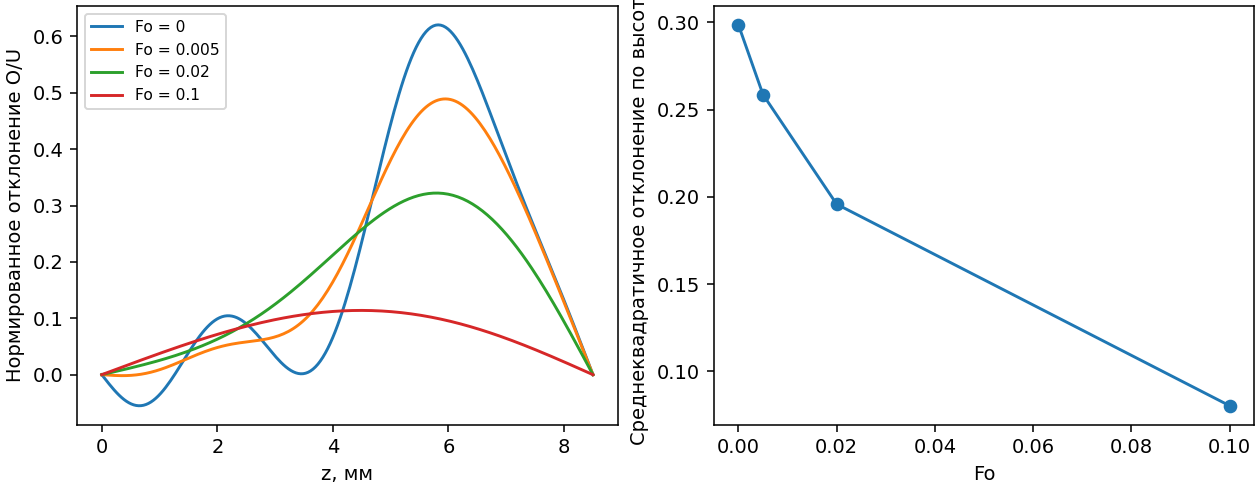

Fo,rms
0.000,0.298571
0.005,0.258652
0.020,0.195841
0.100,0.080385


In [3]:
fig,(ax,ax2)=plt.subplots(1,2,figsize=(9,3.5),layout='constrained')
for f,u in zip(Fo,profiles):ax.plot(H_MM*xi,u,label=f'Fo = {f:g}')
ax.set(xlabel='z, мм',ylabel='Нормированное отклонение O/U');ax.legend(fontsize=8)
ax2.plot(Fo,np.sqrt(energy),'o-');ax2.set(xlabel='Fo',ylabel='Среднеквадратичное отклонение по высоте')
fig.savefig(out/'profiles.png',dpi=140);plt.close(fig);display(Image(filename=str(out/'profiles.png')))
df=pd.concat([pd.DataFrame(dict(Fo=f,z_mm=H_MM*xi,u=u)) for f,u in zip(Fo,profiles)])
df.to_csv(out/'profiles.csv',index=False)
summary=pd.DataFrame(dict(Fo=Fo,rms=np.sqrt(energy)))
summary.to_csv(out/'summary.csv',index=False);display(summary)